In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_squared_error

url = "https://raw.githubusercontent.com/alura-cursos/data_science_projeto/main/Dados/bicicletas.csv"
df = pd.read_csv(url)
df_limpo = df.drop_duplicates()
df_limpo.head()
df_modelo = df_limpo.copy()

In [ ]:
# Garantindo que a coluna de data esteja no formato datetime
df_modelo['data_hora'] = pd.to_datetime(df_modelo['data_hora'])

# Criando colunas derivadas de data
df_modelo['data'] = df_modelo['data_hora'].dt.date
df_modelo['hora'] = df_modelo['data_hora'].dt.hour
df_modelo['mes'] = df_modelo['data_hora'].dt.month

df_modelo.head()



,data_hora,contagem,temperatura,sensacao_termica,umidade,velocidade_vento,clima,feriado,fim_de_semana,estacao,data,hora,mes
0,2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,Nublado,Não,Sim,Inverno,2015-01-04,0,1
1,2015-01-04 01:00:00,138,NaN,NaN,93.0,5.0,Céu limpo,Não,Sim,Inverno,2015-01-04,1,1
2,2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,Céu limpo,Não,Sim,Inverno,2015-01-04,2,1
3,2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,Céu limpo,Não,Sim,Inverno,2015-01-04,3,1
4,2015-01-04 04:00:00,47,NaN,NaN,93.0,6.5,Céu limpo,Não,Sim,Inverno,2015-01-04,4,1


In [ ]:
# Agregando a contagem por dia
df_diario = (df_modelo.groupby('data')['contagem'].sum().reset_index())

# Ajustando nomes das colunas para o Prophet (ds = data, y = valor)
df_prophet = df_diario.rename(columns={'data' : 'ds', 'contagem' : 'y'})

# Convertendo ds para datetime (caso tenha virado date)
df_prophet['ds'] = pd.to_datetime(df_prophet['ds'])

df_prophet.head()

,ds,y
0,2015-01-04,9234
1,2015-01-05,20372
2,2015-01-06,20613
3,2015-01-07,21064
4,2015-01-08,15601


In [ ]:
# Ordenando por data
df_prophet = df_prophet.sort_values('ds').reset_index(drop=True)

# Definindo um corte: 80% dos dados para treino
tamanho_treino = int(len(df_prophet) * 0.8)

df_treino = df_prophet.iloc[:tamanho_treino].copy()
df_teste = df_prophet.iloc[tamanho_treino:].copy()

len(df_treino), len(df_teste)

(584, 146)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


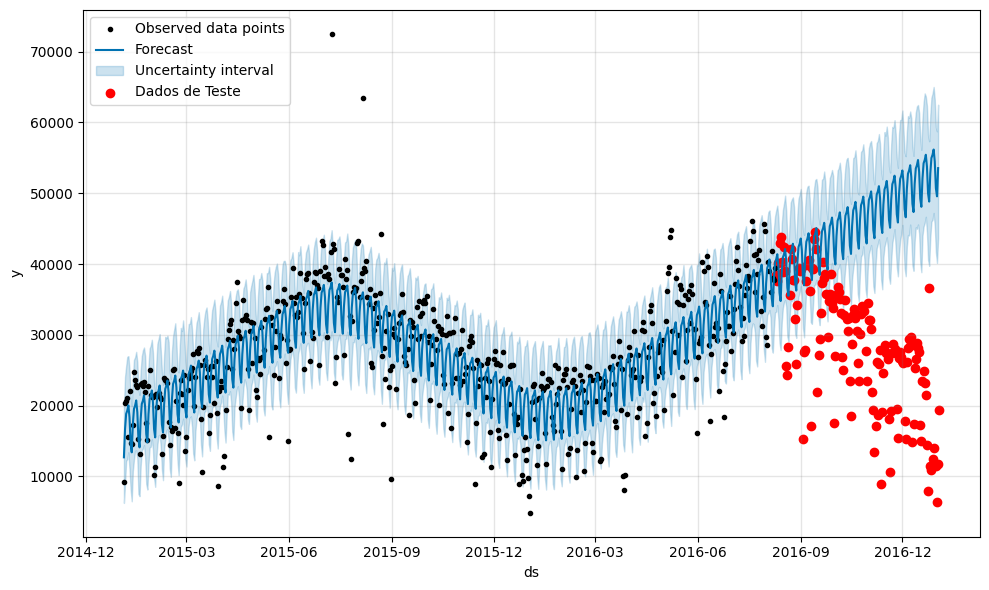

In [ ]:
# Fixando semente aleatória para reprodutibilidade
np.random.seed(4587)

# Criando e ajustando o modelo Prophet básico
modelo_basico = Prophet()
modelo_basico.fit(df_treino)

# Criando datas futuras (apenas até o fim do período de teste)
periodos_futuros = len(df_teste)
futuro = modelo_basico.make_future_dataframe(periods=periodos_futuros, freq = 'D')

# Fazendo previsões
previsao_basica = modelo_basico.predict(futuro)

# Visualizando o gráfico com os dados reais de teste
fig1 = modelo_basico.plot(previsao_basica)
plt.scatter(df_teste['ds'], df_teste['y'], color = 'red', label='Dados de Teste')
plt.legend()
plt.show()

In [ ]:
# Juntando previsões e valores reais do teste
previsoes_teste = previsao_basica[['ds', 'yhat']].merge(df_teste, on='ds', how='inner')
mse_basico = mean_squared_error(previsoes_teste['y'], previsoes_teste['yhat'])
rmse_basico = np.sqrt(mse_basico)

print(f'MSE: {mse_basico:.2f}')
print(f'RMSE: {rmse_basico:.2f}')

MSE: 460270443.80
RMSE: 21453.91


In [ ]:
# Modelo com sazonalidade anual habilitada
np.random.seed(4587)
modelo_anual = Prophet(yearly_seasonality=True)
modelo_anual.fit(df_treino)

futuro_anual = modelo_anual.make_future_dataframe(periods=periodos_futuros, freq = 'D')
previsao_anual = modelo_anual.predict(futuro_anual)


# Comparando com os dados de teste
previsoes_teste_anual = previsao_anual[['ds', 'yhat']].merge(df_teste, on='ds', how='inner')
mse_anual = mean_squared_error(previsoes_teste_anual['y'], previsoes_teste_anual['yhat'])
rmse_anual = np.sqrt(mse_anual)

print(f'MSE (modelo anual): {mse_anual:.2f}')
print(f'RMSE (modelo anual): {rmse_anual:.2f}')

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


MSE (modelo anual): 38844343.99
RMSE (modelo anual): 6232.52


In [ ]:
# Ajustando Prophet em Ttodos os dados para detectar outliers
modelo_outliers = Prophet(yearly_seasonality=True)
modelo_outliers.fit(df_prophet)

# Sem períodos futuros: apenas as datas existentes
futuro_treino = modelo_outliers.make_future_dataframe(periods=0)
previsao_treino = modelo_outliers.predict(futuro_treino)

# Unindo previsão e dados reais
df_outlier = df_prophet.merge(previsao_treino[['ds', 'yhat_lower', 'yhat_upper']], on='ds', how='left')

# Mantendo apenas pontos dentro do intervalo [yhat_lower, yhat_upper]
sem_outliers = df_outlier[(df_outlier['y'] >= df_outlier['yhat_lower']) & (df_outlier['y'] <= df_outlier['yhat_upper'])][['ds', 'y']].reset_index(drop=True)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [ ]:
# Ordenando e separando treino/teste novamente com dados sem outliers
sem_outliers = sem_outliers.sort_values('ds').reset_index(drop=True)

tamanho_treino_sem_outliers = int(len(sem_outliers) * 0.8)
df_treino_sem_outliers = sem_outliers.iloc[:tamanho_treino_sem_outliers].copy()
df_teste_sem_outliers = sem_outliers.iloc[tamanho_treino_sem_outliers:].copy()

# Novo modelo Prophet com sazonalidade anual, sem outliers
np.random.seed(4587)
modelo_sem_outliers = Prophet(yearly_seasonality=True)
modelo_sem_outliers.fit(df_treino_sem_outliers)

futuro_sem_outliers = modelo_sem_outliers.make_future_dataframe(periods=len(df_teste_sem_outliers), freq='D')
previsao_sem_outliers = modelo_sem_outliers.predict(futuro_sem_outliers)

previsoes_teste_sem_outliers = previsao_sem_outliers[['ds', 'yhat']].merge(df_teste_sem_outliers, on='ds', how='inner')

mse_sem_outliers = mean_squared_error(previsoes_teste_sem_outliers['y'], previsoes_teste_sem_outliers['yhat'])
rmse_sem_outliers = np.sqrt(mse_sem_outliers)

print(f'mse (sem outliers): {mse_sem_outliers:.2f}')
print(f'rmse (sem outlier): {rmse_sem_outliers:.2f}')

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


mse (sem outliers): 14014686.32
rmse (sem outlier): 3743.62
